# PS 3A
Implement credit card fraud detection for given credit card fraud detection Kaggle
dataset using Autoencoder and build the model by using the following steps:
  
  • Dataset: The dataset contains transactions labeled as fraudulent or non-fraudulent, with
a severe class imbalance.

  
  • Goal: Identify fraudulent transactions by training an autoencoder only on non-
fraudulent transactions.

  
  Steps:
  
  • Preprocess the data by scaling features (features are already PCA-transformed, so
they’re anonymized).
  
  • Train an autoencoder on non-fraudulent transactions to learn typical spending patterns.
  
  • Calculate reconstruction errors for transactions and set a threshold to detect fraud.
  
  • Compile the models with Optimizer, Loss, and Evaluation Metrics

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

from tensorflow.keras import models, layers, optimizers

In [2]:
# LOADING DATASET
df = pd.read_csv("creditcard.csv")
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
print(df.shape)
# print(df.info())
print(df['Class'].isnull().sum().sum())

(284807, 31)
0


In [4]:
# SEPARATING X AND Y
X = df.drop(columns=["Class", "Time"])
y = df["Class"]

In [5]:
# SPLIT AND SCALE THE DATA
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [6]:
# SEPARATING NORMAL AND FRAUD TRANSACTION
X_train = X_train[y_train == 0]

In [7]:
# DEFINING AUTOENCODER ARCHITECTURE

#ENCODER
encoder = models.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu")
])

# DECODER
decoder = models.Sequential([
    layers.Input(shape=(8,)),
    layers.Dense(16, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(X_train.shape[1], activation="sigmoid")
])

# AUTOENCODER
model = models.Sequential([encoder, decoder])

#model.summary()
#encoder.summary()
#decoder.summary()

In [8]:
# COMPILE THE MODEL
model.compile(
    optimizer = 'adam',
    loss = "mse",
    metrics = ["mae"]
)

In [9]:
# TRAIN THE MODEL
history = model.fit(
    X_train, X_train,
    epochs = 10,
    batch_size = 256,
    validation_split = 0.1
)

Epoch 1/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - loss: 0.8791 - mae: 0.6126 - val_loss: 0.7869 - val_mae: 0.5759
Epoch 2/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.7971 - mae: 0.5677 - val_loss: 0.7673 - val_mae: 0.5627
Epoch 3/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.7823 - mae: 0.5569 - val_loss: 0.7541 - val_mae: 0.5530
Epoch 4/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - loss: 0.7709 - mae: 0.5489 - val_loss: 0.7445 - val_mae: 0.5461
Epoch 5/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.7646 - mae: 0.5445 - val_loss: 0.7427 - val_mae: 0.5464
Epoch 6/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - loss: 0.7600 - mae: 0.5412 - val_loss: 0.7348 - val_mae: 0.5399
Epoch 7/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - loss: 0.7559 - mae: 0.5391 - val_loss: 0.7318 - val_mae: 0.5384
Epoch 8/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.7523 - mae: 0.5366 - val_loss: 0.7291 - val_mae: 0.5365
Epoch 9/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - lo

In [10]:
# CALCULATE RECONSTRUCTION ERROR
train_predictions = model.predict(X_train)

train_errors = np.mean(
    np.square(X_train - train_predictions), axis = 1 
)

7108/7108 ━━━━━━━━━━━━━━━━━━━━ 12s 2ms/step


In [11]:
# SETTING THE THRESHOLD TO 95TH PERCENTILE
threshold = np.percentile(train_errors, 95 )

print("Threshold: ", threshold)

Threshold:  1.5342034550418617


In [12]:
# DETECT FRAUDENT TRANSACTIONS
test_predictions = model.predict(X_test)

test_errors = np.mean(
    np.square(X_test - test_predictions), axis = 1 
)

y_pred = (test_errors > threshold).astype(int)

print("Reconstruction Errors:")
print(test_errors[:10])

print("Predicted Classes:")
print(y_pred[:10])

1781/1781 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step
Reconstruction Errors:
[0.23877564 1.09020611 2.42658732 0.22619883 1.26835938 0.22996523
 0.68041052 0.2782387  0.17341161 0.39056212]
Predicted Classes:
[0 0 1 0 0 0 0 0 0 0]


In [13]:
y_pred

array([0, 0, 1, ..., 0, 0, 0])

In [14]:
# EVALUATE MODEL PERFORMANCE
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[53939  2925]
 [   11    87]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.95      0.97     56864
           1       0.03      0.89      0.06        98

    accuracy                           0.95     56962
   macro avg       0.51      0.92      0.51     56962
weighted avg       1.00      0.95      0.97     56962



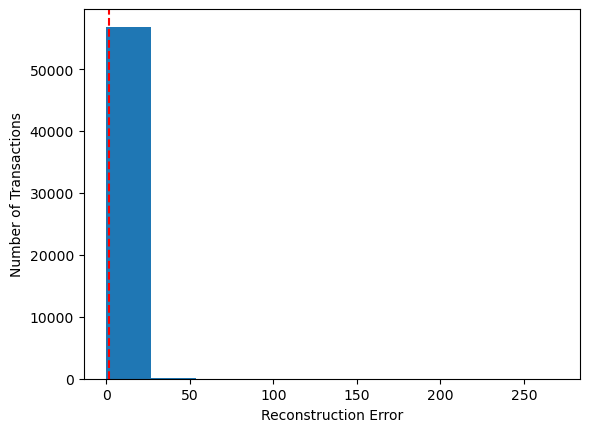

In [15]:
plt.hist(test_errors, bins=10)
plt.axvline(threshold, color='red', linestyle='--')
plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Transactions")
plt.show()